## Setup

In [8]:
import os, re, math
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    classification_report, accuracy_score, f1_score, recall_score, ConfusionMatrixDisplay
)
from scipy.stats import binomtest
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
import textwrap

SEED = 42
VAL_SIZE = 0.15
DATA_PATH = 'ternary_academic_wiki_512.csv'
MODEL_NAME = 'roberta-base'
MAX_LENGTH = 512
LR = 2e-5
EPOCHS = 3
TRAIN_BS = 16
EVAL_BS = 64
WEIGHT_DECAY = 0.01
WARMUP_FRAC = 0.1
OUTPUT_DIR = 'roberta_ft_out'

LABELS = ['human', 'ai_generated', 'ai_refined']
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

# ---- prediction files to compare (same truncation length for both) ----
FT_PATH = 'test_predictions_roberta_finetuned.csv'
FROZEN_PATH = 'test_predictions_roberta_frozen_lr.csv'


for p in (FT_PATH, FROZEN_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(f'{p} not found.')


def load_pred(path):
    r = pd.read_csv(path)
    miss = {'text', 'label', 'prediction'} - set(r.columns)
    assert not miss, f'{path} is missing columns: {miss}'
    return r


ft = load_pred(FT_PATH)
fz = load_pred(FROZEN_PATH)
assert len(ft) == len(fz), (f'Different test sizes: fine-tuned {len(ft)} vs frozen {len(fz)}. '
                            'Were both run on the same data file?')
if 'max_length' in ft.columns:
    assert (ft['max_length'] == MAX_LENGTH).all(), 'Fine-tuned CSV was produced with a different MAX_LENGTH.'

ft_cols = [c for c in ['text', 'label', 'pair_id', 'domain', 'model', 'confidence'] if c in ft.columns]
same_order = ((ft['text'].to_numpy() == fz['text'].to_numpy()).all()
              and (ft['label'].to_numpy() == fz['label'].to_numpy()).all())
if same_order:
    cmp = ft[ft_cols].copy()
    cmp['pred_ft'] = ft['prediction'].to_numpy()
    cmp['pred_frozen'] = fz['prediction'].to_numpy()
else:
    key = ['text', 'label']
    assert not ft.duplicated(key).any() and not fz.duplicated(key).any(), \
        'Rows differ in order and texts are not unique, cannot align the two files.'
    cmp = (ft[ft_cols + ['prediction']].rename(columns={'prediction': 'pred_ft'})
           .merge(fz[key + ['prediction']].rename(columns={'prediction': 'pred_frozen'}),
                  on=key, how='inner', validate='one_to_one'))
    assert len(cmp) == len(ft), f'Only {len(cmp)} of {len(ft)} rows matched between the two files.'
cmp = cmp.rename(columns={'confidence': 'ft_confidence'}).reset_index(drop=True)

assert (set(cmp['pred_ft']) | set(cmp['pred_frozen'])) <= set(LABELS), 'Unexpected predicted labels.'
y = cmp['label'].to_numpy()
cmp['ft_correct'] = cmp['pred_ft'] == cmp['label']
cmp['frozen_correct'] = cmp['pred_frozen'] == cmp['label']
cmp['n_words'] = cmp['text'].str.split().str.len()

print(f'MAX_LENGTH = {MAX_LENGTH}')
print(f'fine-tuned file: {FT_PATH}')
print(f'frozen file:     {FROZEN_PATH}')
print(f'rows aligned: {len(cmp):,} (same row order: {same_order})')
print(f'identical predictions on {(cmp.pred_ft == cmp.pred_frozen).mean():.1%} of texts')
display(cmp['label'].value_counts().rename('test texts').to_frame())

MAX_LENGTH = 512
fine-tuned file: test_predictions_roberta_finetuned.csv
frozen file:     test_predictions_roberta_frozen_lr.csv
rows aligned: 1,500 (same row order: True)
identical predictions on 91.3% of texts


,test texts
label,
human,500
ai_generated,500
ai_refined,500


Display matched texts with predictions

In [10]:
def show_triplet(pair_id):
    group = cmp[
        cmp["pair_id"].astype(str) == str(pair_id)
    ].copy()

    if group.empty:
        print("Pair ID not found.")
        return

    group = group.set_index("label").loc[LABELS].reset_index()

    for _, row in group.iterrows():
        print("\n" + "=" * 90)
        print("Actual:", row["label"])
        print("Frozen:", row["pred_frozen"])
        print("Fine-tuned:", row["pred_ft"])
        print(f"Confidence: {row['ft_confidence']:.4f}")
        print("Word count:", row["n_words"])
        print("\n" + row["text"])


# Fine-tuned model succeeds
show_triplet("36852")
show_triplet("38916")

# Frozen model succeeds
show_triplet("38782")

# Both models fail
show_triplet("110902")


Actual: human
Frozen: human
Fine-tuned: human
Confidence: 0.9993
Word count: 305

The Delahaye 145 is a luxury car, derived from a racecar design, manufactured by French automaker Delahaye. Based on a sporting tourer, it was designed to be capable for racing. History Only four 4.5 litre naturally aspirated V12 Type 145 racecars were built, all exclusively for Lucy O'Reilly Schell and her Écurie Bleue racing team. These were build numbers 48771, 48772, 48773, and 48775. The missing chassis number in the sequence, 48774, was the only Type 155 built — a grandprix monoposto fitted with an experimental De Dion tube independent rear suspension system and innovative geared hubs. All five of the V12 engined chassis were based on the wheelbase Type 135SC. The only difference in the Type 145 was a pair of short rear suspension trailing arms that were supposed to improve handling. The chassis of the Type 155 was an original one-off that used only the Type 135's proprietary independent front susp

Show text difference in triplet observations

In [ ]:
from difflib import SequenceMatcher
from IPython.display import HTML, display
from html import escape


def show_revision(pair_id):
    group = cmp[
        cmp["pair_id"].astype(str) == str(pair_id)
    ]

    original = group.loc[
        group["label"] == "human", "text"
    ].iloc[0]

    refined = group.loc[
        group["label"] == "ai_refined", "text"
    ].iloc[0]

    a = original.split()
    b = refined.split()

    matcher = SequenceMatcher(None, a, b, autojunk=False)
    output = []

    for tag, i1, i2, j1, j2 in matcher.get_opcodes():
        old = escape(" ".join(a[i1:i2]))
        new = escape(" ".join(b[j1:j2]))

        if tag == "equal":
            output.append(old)

        if tag in ["delete", "replace"]:
            output.append(
                f'<span style="background:#ffd6d6;'
                f'color:#842020;text-decoration:line-through">'
                f'{old}</span>'
            )

        if tag in ["insert", "replace"]:
            output.append(
                f'<span style="background:#d6f5d6;'
                f'color:#205a20">{new}</span>'
            )

    print("Pair ID:", pair_id)
    print("Token sequence similarity:", round(matcher.ratio(), 4))

    display(HTML(
        '<div style="line-height:2">'
        + " ".join(output) + "</div>"
    ))

# High confidence mistakes on ai_refined texts
show_revision("38782") # true: ai_refined, pred: ai_generated
show_revision("38913") # true: ai_refined, pred: human
show_revision("110902") # true: ai_refined, pred: ai_generated, both models fail

# Fixed TBA (note that show_revision only applies for ai-refined class)

# Worse TBA

Pair ID: 38782
Token sequence similarity: 0.5821


Pair ID: 38913
Token sequence similarity: 0.7701


Pair ID: 110902
Token sequence similarity: 0.4669


## Linguistic Features Analysis

In [12]:
!pip -q install spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 35.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [13]:
import spacy
from collections import Counter

nlp = spacy.load("en_core_web_sm")

TRANSITIONS = [
    "however",
    "furthermore",
    "moreover",
    "therefore",
    "consequently",
    "additionally",
    "notably",
    "in contrast",
    "in addition",
    "as a result",
    "in conclusion",
    "overall",
    "in particular"
]


def mattr(words, window=50):
    if len(words) < window:
        return len(set(words)) / max(len(words), 1)

    return np.mean([
        len(set(words[i:i + window])) / window
        for i in range(len(words) - window + 1)
    ])


def linguistic_features(doc):
    tokens = [t for t in doc if t.is_alpha]
    words = [t.lower_ for t in tokens]
    n = max(len(tokens), 1)

    pos = Counter(t.pos_ for t in tokens)

    sent_lengths = [
        sum(t.is_alpha for t in sent)
        for sent in doc.sents
    ]

    sent_lengths = [x for x in sent_lengths if x > 0]

    text = doc.text.lower()

    transitions = sum(
        len(re.findall(
            r"\b" + re.escape(word) + r"\b", text
        ))
        for word in TRANSITIONS
    )

    bigrams = list(zip(words, words[1:]))

    repeated_bigrams = (
        1 - len(set(bigrams)) / len(bigrams)
        if bigrams else 0
    )

    subordinate_clauses = sum(
        t.dep_ in ["advcl", "ccomp", "relcl"]
        for t in doc
    )

    passive = sum(
        t.dep_ in ["nsubjpass", "auxpass"]
        for t in doc
    )

    return {
        "mattr": mattr(words),
        "mean_word_length": np.mean(
            [len(w) for w in words] or [0]
        ),
        "mean_sentence_length": np.mean(
            sent_lengths or [0]
        ),
        "sentence_length_std": np.std(
            sent_lengths or [0]
        ),
        "adjective_ratio": pos["ADJ"] / n,
        "adverb_ratio": pos["ADV"] / n,
        "noun_ratio": pos["NOUN"] / n,
        "pronoun_ratio": pos["PRON"] / n,
        "verb_ratio": pos["VERB"] / n,
        "proper_noun_ratio": pos["PROPN"] / n,
        "subordinate_clause_rate":
            subordinate_clauses / n * 100,
        "passive_dependency_rate": passive / n * 100,
        "transition_rate": transitions / n * 100,
        "repeated_bigram_ratio": repeated_bigrams,
        "named_entity_rate": len(doc.ents) / n * 100,
        "citation_rate": len(re.findall(
            r"\([^()]*\b(?:19|20)\d{2}\b[^()]*\)",
            doc.text
        )) / n * 100
    }


features = pd.DataFrame([
    linguistic_features(doc)
    for doc in nlp.pipe(
        cmp["text"].tolist(),
        batch_size=32
    )
])

analysis_df = pd.concat(
    [cmp.reset_index(drop=True), features],
    axis=1
)

display(features.head())

,mattr,mean_word_length,mean_sentence_length,sentence_length_std,adjective_ratio,adverb_ratio,noun_ratio,pronoun_ratio,verb_ratio,proper_noun_ratio,subordinate_clause_rate,passive_dependency_rate,transition_rate,repeated_bigram_ratio,named_entity_rate,citation_rate
0,0.835939,4.980645,23.846154,18.814259,0.070968,0.025806,0.200000,0.051613,0.087097,0.277419,4.193548,1.935484,0.0,0.135922,16.774194,0.0
1,0.848658,5.621429,21.538462,4.430929,0.107143,0.014286,0.264286,0.039286,0.103571,0.189286,3.571429,0.357143,0.0,0.082437,10.000000,0.0
2,0.867228,5.223108,19.307692,15.288933,0.071713,0.011952,0.235060,0.027888,0.083665,0.314741,3.187251,1.992032,0.0,0.112000,19.123506,0.0
3,0.802105,4.704762,16.578947,8.241843,0.063492,0.047619,0.238095,0.044444,0.076190,0.190476,1.904762,1.904762,0.0,0.101911,14.920635,0.0
4,0.842176,4.946281,24.200000,8.669487,0.119835,0.033058,0.268595,0.041322,0.090909,0.123967,2.066116,1.239669,0.0,0.058091,12.809917,0.0


Group by prediction classes.

In [20]:
GROUP_ORDER = [
    "Correct Human",
    "Correct AI-refined",
    "Human mispredicted as AI-refined"
]

MODEL_ORDER = [
    "Frozen RoBERTa",
    "Fine-tuned RoBERTa"
]

grouped_dfs = []

for model_name, pred_col in [
    ("Frozen RoBERTa", "pred_frozen"),
    ("Fine-tuned RoBERTa", "pred_ft")
]:
    df = analysis_df.copy()

    df["classifier"] = model_name

    df["group"] = np.select(
        [
            (df["label"] == "human") &
            (df[pred_col] == "human"),

            (df["label"] == "ai_refined") &
            (df[pred_col] == "ai_refined"),

            (df["label"] == "human") &
            (df[pred_col] == "ai_refined")
        ],
        GROUP_ORDER,
        default="Other"
    )

    grouped_dfs.append(
        df[df["group"] != "Other"]
    )

ling_df = pd.concat(
    grouped_dfs,
    ignore_index=True
)

ling_df["group"] = pd.Categorical(
    ling_df["group"],
    categories=GROUP_ORDER,
    ordered=True
)

display(pd.crosstab(
    ling_df["group"],
    ling_df["classifier"]
))

classifier,Fine-tuned RoBERTa,Frozen RoBERTa
group,,
Correct Human,456,422
Correct AI-refined,482,471
Human mispredicted as AI-refined,44,76


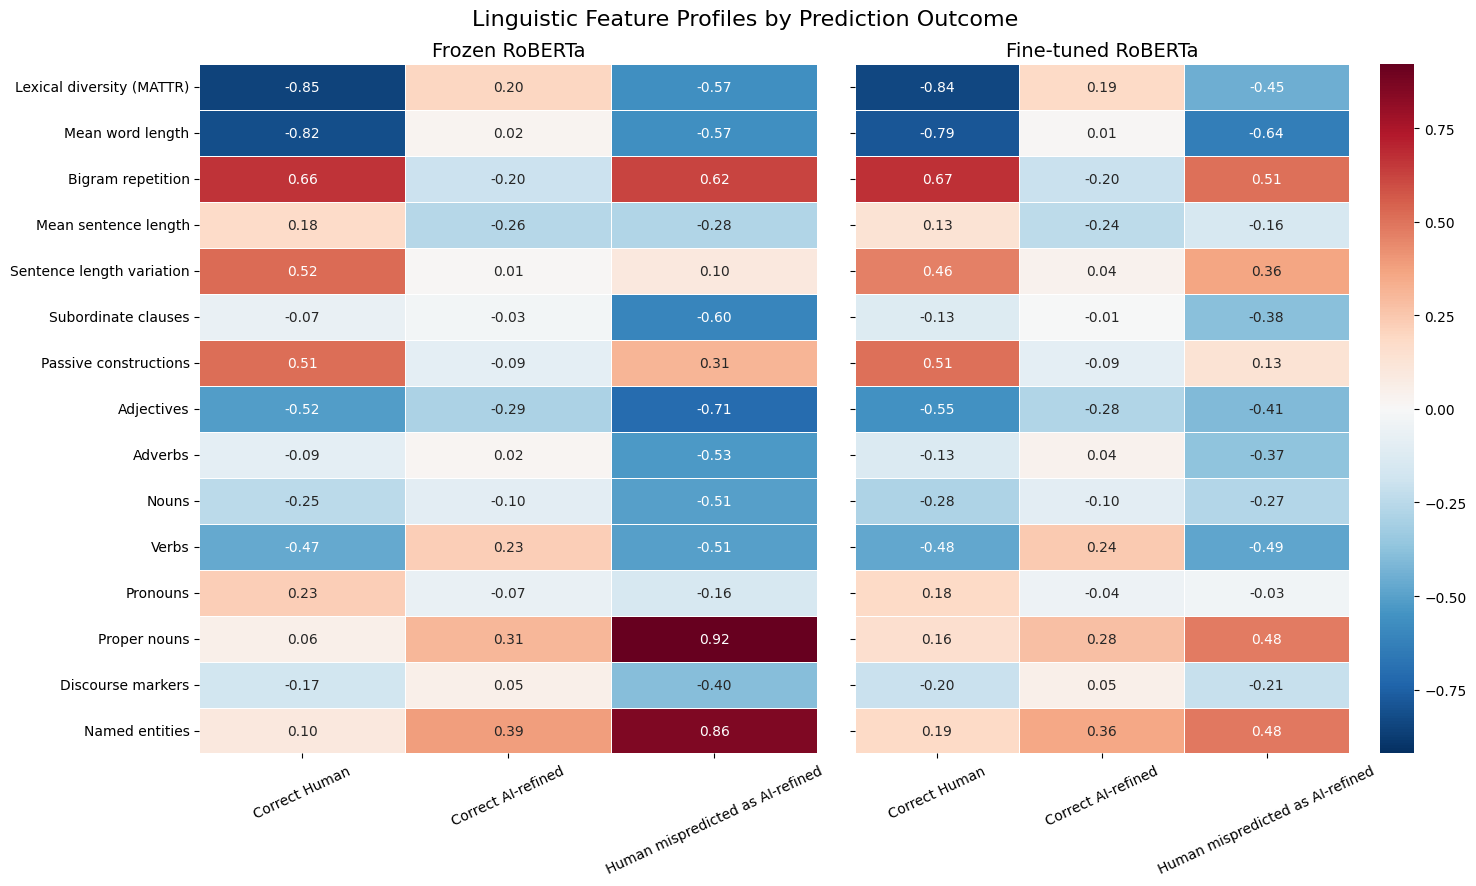

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

FEATURE_NAMES = {
    "mattr": "Lexical diversity (MATTR)",
    "mean_word_length": "Mean word length",
    "repeated_bigram_ratio": "Bigram repetition",
    "mean_sentence_length": "Mean sentence length",
    "sentence_length_std": "Sentence length variation",
    "subordinate_clause_rate": "Subordinate clauses",
    "passive_dependency_rate": "Passive constructions",
    "adjective_ratio": "Adjectives",
    "adverb_ratio": "Adverbs",
    "noun_ratio": "Nouns",
    "verb_ratio": "Verbs",
    "pronoun_ratio": "Pronouns",
    "proper_noun_ratio": "Proper nouns",
    "transition_rate": "Discourse markers",
    "named_entity_rate": "Named entities"
}

FEATURE_COLS = list(FEATURE_NAMES.keys())

# Shared normalization reference
mu = analysis_df[FEATURE_COLS].mean()
sigma = analysis_df[FEATURE_COLS].std().replace(0, 1)

z_df = ling_df.copy()

z_df[FEATURE_COLS] = (
    z_df[FEATURE_COLS] - mu
) / sigma

summary = (
    z_df.groupby(
        ["classifier", "group"],
        observed=True
    )[FEATURE_COLS]
    .mean()
)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 9),
    sharey=True
)

vmax = max(
    0.5, np.nanmax(np.abs(summary.to_numpy()))
)

for ax, model in zip(axes, MODEL_ORDER):

    data = (
        summary.loc[model]
        .reindex(GROUP_ORDER)
        .T
        .rename(index=FEATURE_NAMES)
    )

    sns.heatmap(
        data,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-vmax,
        vmax=vmax,
        linewidths=0.5,
        cbar=(model == MODEL_ORDER[-1]),
        ax=ax
    )

    ax.set_title(model, fontsize=14)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=25)

plt.suptitle(
    "Linguistic Feature Profiles by Prediction Outcome",
    fontsize=16
)

plt.tight_layout()
plt.show()